# Actividad 04 Clustering en Iris Moons y Circle
## Proyecto nuevo adaptado a Google Colab
Este notebook conserva los datos, escalado y parámetros del ZIP recibido. Añade explicaciones, sensibilidad, tablas de contingencia, datos exportados y registro de versiones.

**Cómo usarlo:** Archivo → Subir notebook → seleccionar este archivo → Ejecutar todas. No necesitas cargar otros archivos, montar Drive ni usar GPU. Los datos se cargan o generan con scikit-learn. Si cambias parámetros, vuelve a ejecutar todo para reiniciar las listas de resultados.

**Integrantes:** completar hasta cuatro nombres. El informe editable se entrega por separado en Word. No se publica nada en GitHub.

Las salidas incluidas proceden de ejecutar las celdas secuencialmente en Python local, no del servicio Colab.

## 1 Entender el experimento
El clustering agrupa sin entrenar con las clases reales. K-means usa centroides; DBSCAN conecta zonas densas; Spectral utiliza un grafo de vecinos.

Iris se estandariza y se entrena en cuatro variables. Sus figuras muestran longitud y ancho del pétalo, no PCA. Moons y Circle conservan sus coordenadas originales. Se fija k=3 para Iris y k=2 para los sintéticos según el número conocido de clases: es un supuesto del ejemplo.

| Métrica | Qué mide | Mejor valor |
|---|---|---|
| ARI | Coincidencia de pares corregida por azar | 1; cerca de 0 equivale a azar; puede ser negativo |
| V-measure | Homogeneidad y completitud | 1 |
| Silhouette | Separación geométrica respecto al grupo propio | Cerca de 1 |
| Davies-Bouldin | Dispersión respecto a separación entre centroides | Menor |
| Codo | Cambio de pendiente de la inercia de K-means | No es una puntuación universal |

ARI y V incluyen el ruido como etiqueta -1; las métricas internas excluyen ruido. Se informa cobertura. No se calculan métricas internas cuando no existen entre 2 y n−1 grupos válidos.

## 2 Importar y definir funciones
Se emplean las mismas funciones de evaluación y gráficos del proyecto nuevo. Los colores de cada panel son identificadores arbitrarios de grupos.

In [1]:
"""Experimento reproducible para la Actividad 04."""
import csv
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import DBSCAN, KMeans, SpectralClustering
from sklearn.datasets import load_iris, make_circles, make_moons
from sklearn.metrics import (adjusted_rand_score, davies_bouldin_score,
                             silhouette_score, v_measure_score)
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

SEED = 42
OUTPUT = Path("resultados")
OUTPUT.mkdir(exist_ok=True)
COLORS = ["#007F86", "#B74B24", "#5148A0", "#549229", "#B72864"]


def kmeans(k):
    return KMeans(n_clusters=k, n_init=20, random_state=SEED)


def evaluate(name, model, x, truth, labels):
    assigned = labels != -1
    groups = len(np.unique(labels[assigned]))
    valid = 2 <= groups < assigned.sum()
    return {
        "dataset": name, "modelo": model, "grupos": groups,
        "ruido": int((~assigned).sum()), "cobertura": float(assigned.mean()),
        "ARI": adjusted_rand_score(truth, labels),
        "V-measure": v_measure_score(truth, labels),
        "Silhouette": silhouette_score(x[assigned], labels[assigned]) if valid else None,
        "Davies-Bouldin": davies_bouldin_score(x[assigned], labels[assigned]) if valid else None,
    }


def plot_case(name, x, partitions, ks, inertias):
    fig, axes = plt.subplots(1, 4, figsize=(11.5, 2.9), sharex=True, sharey=True,
                             layout="constrained")
    columns = (2, 3) if name == "Iris" else (0, 1)
    for ax, (title, labels) in zip(axes, partitions.items()):
        for label in np.unique(labels):
            points = x[labels == label]
            noise = label == -1
            ax.scatter(points[:, columns[0]], points[:, columns[1]],
                       s=12, marker="x" if noise else "o",
                       color="#53616B" if noise else COLORS[label % len(COLORS)],
                       alpha=.80)
        ax.set_title(title, fontsize=11, weight="bold")
        ax.grid(alpha=.18)
    fig.supxlabel("Longitud del pétalo (z)" if name == "Iris" else "Coordenada X")
    fig.supylabel("Ancho del pétalo (z)" if name == "Iris" else "Coordenada Y")
    fig.savefig(OUTPUT / f"{name}_grupos.png", dpi=175)
    plt.close(fig)
    fig, ax = plt.subplots(figsize=(5.2, 2.5), layout="constrained")
    ax.plot(ks, inertias, "o-", color="#007F86")
    ax.set(xlabel="Número de grupos (k)", ylabel="Inercia", xticks=ks)
    ax.grid(alpha=.23)
    fig.savefig(OUTPUT / f"{name}_codo.png", dpi=175)
    plt.close(fig)


def write_csv(filename, rows):
    with (OUTPUT / filename).open("w", newline="", encoding="utf-8") as file:
        writer = csv.DictWriter(file, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)




## 3 Preparar los datos y parámetros
Semilla 42. Moons: noise=0.045. Circle: factor=0.45 y noise=0.035. DBSCAN: min_samples=5. Spectral: 12 vecinos.

In [2]:
# Mismas configuraciones del proyecto recibido
iris, iris_labels = load_iris(return_X_y=True)
moons, moons_labels = make_moons(n_samples=500, noise=.045, random_state=SEED)
circles, circle_labels = make_circles(n_samples=500, factor=.45, noise=.035, random_state=SEED)
cases = [
    ("Iris", StandardScaler().fit_transform(iris), iris_labels, 3, .5, 5, 12),
    ("Moons", moons, moons_labels, 2, .16, 5, 12),
    ("Circle", circles, circle_labels, 2, .15, 5, 12),
]
metrics, elbows = [], []
ks = list(range(1, 11))
# Limitar hilos también hace más ágil este ejemplo pequeño.
threadpool_limits(limits=1)
print('Datos preparados: Iris 150×4; Moons y Circle 500×2. Semilla 42.')


Datos preparados: Iris 150×4; Moons y Circle 500×2. Semilla 42.


## 4 Preparar el entrenamiento
El evaluador nunca entrega las clases reales a fit_predict. Se guardan tablas de contingencia y avisos de conectividad.

In [3]:
import warnings
import pandas as pd
from sklearn.neighbors import kneighbors_graph
from scipy.sparse.csgraph import connected_components
predictions, notices, graph_info = {}, [], []
def run_case(case):
    name,x,truth,k,eps,min_samples,neighbors = case
    models = {'K-means': kmeans(k), 'DBSCAN': DBSCAN(eps=eps,min_samples=min_samples),
              'Spectral': SpectralClustering(n_clusters=k,affinity='nearest_neighbors',
                    n_neighbors=neighbors,assign_labels='kmeans',n_init=20,random_state=SEED)}
    partitions={'Referencia':truth}
    for model_name, model in models.items():
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always')
            labels=model.fit_predict(x)
        notices.extend({'dataset':name,'modelo':model_name,'aviso':str(w.message)} for w in caught)
        partitions[model_name]=labels
        predictions[(name,model_name)]=labels
        metrics.append(evaluate(name,model_name,x,truth,labels))
        pd.crosstab(pd.Series(truth,name='clase_real'),pd.Series(labels,name='cluster')).to_csv(OUTPUT/f'{name}_{model_name}_contingencia.csv')
    A=kneighbors_graph(x,n_neighbors=neighbors,include_self=True)
    graph_info.append({'dataset':name,'componentes':connected_components(A.maximum(A.T),directed=False)[0]})
    inertias=[kmeans(candidate).fit(x).inertia_ for candidate in ks]
    elbows.extend({'dataset':name,'k':candidate,'inercia':inertia} for candidate,inertia in zip(ks,inertias))
    plot_case(name,x,partitions,ks,inertias)
    print(pd.DataFrame([r for r in metrics if r['dataset']==name]).round(4).to_string(index=False))
    for filename in [f'{name}_grupos.png',f'{name}_codo.png']:
        fig,ax=plt.subplots(figsize=(12,3.5) if 'grupos' in filename else (7,3.5))
        ax.imshow(plt.imread(OUTPUT/filename)); ax.axis('off'); fig.tight_layout(); plt.show(); plt.close(fig)


## 5 Caso Iris
150 flores, cuatro medidas de sépalo y pétalo y tres especies de referencia. Los modelos utilizan las cuatro variables estandarizadas. El gráfico muestra dos de ellas.

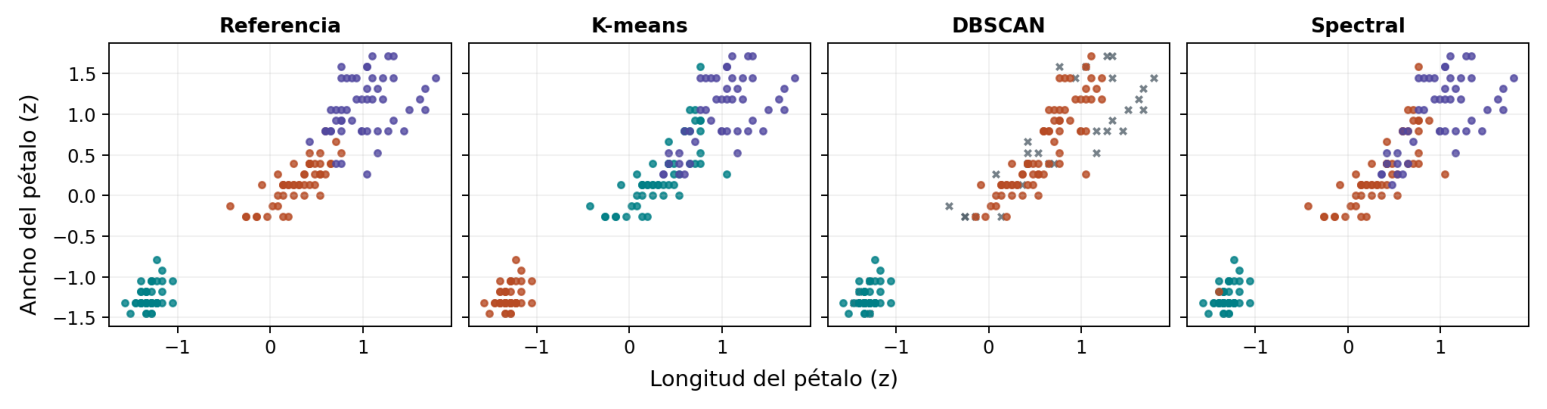

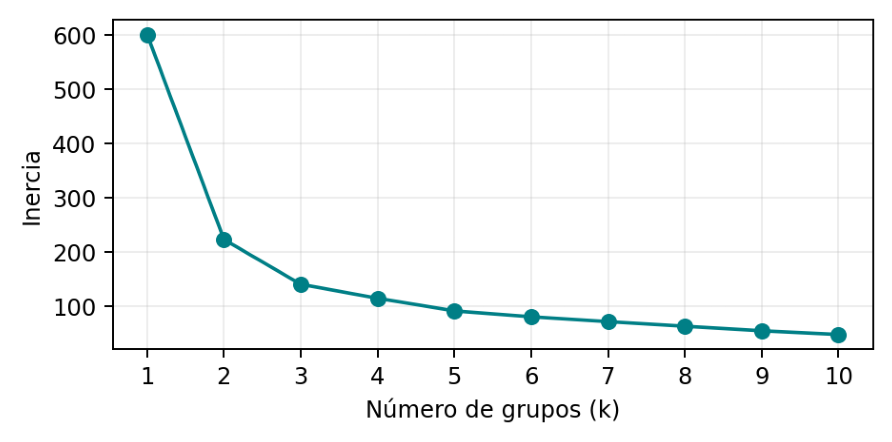

dataset   modelo  grupos  ruido  cobertura    ARI  V-measure  Silhouette  Davies-Bouldin
   Iris  K-means       3      0     1.0000 0.6201     0.6595      0.4599          0.8336
   Iris   DBSCAN       2     34     0.7733 0.4421     0.5114      0.6559          0.4942
   Iris Spectral       3      0     1.0000 0.5801     0.6166      0.4602          0.8322


In [4]:
run_case(cases[0])

### Interpretación
K-means (ARI 0,620) logra la mayor coincidencia con las especies. La setosa queda bien separada, mientras que versicolor y virginica se superponen en parte. Spectral obtiene tres grupos, con una coincidencia algo menor (ARI 0,580). DBSCAN encuentra dos grupos y deja 34 flores como ruido.

DBSCAN lidera las métricas internas (0,656 y 0,494), calculadas sobre 116 de 150 flores. Su cobertura de 77,3 % y su V-measure de 0,511 limitan la comparación con los modelos que agrupan todas las muestras. K-means presenta la mayor V-measure (0,659).

La inercia baja de 600,00 a 222,36 y luego a 139,82 para k = 1, 2 y 3. El descenso se modera después de k = 3, aunque k = 2 también marca una caída fuerte. Se fijó k = 3 por el diseño del caso.

## 6 Caso Moons
500 observaciones, dos coordenadas y dos medias lunas entrelazadas. Se usó ruido gaussiano con desviación estándar de 0,045. Los modelos trabajan con las coordenadas generadas.

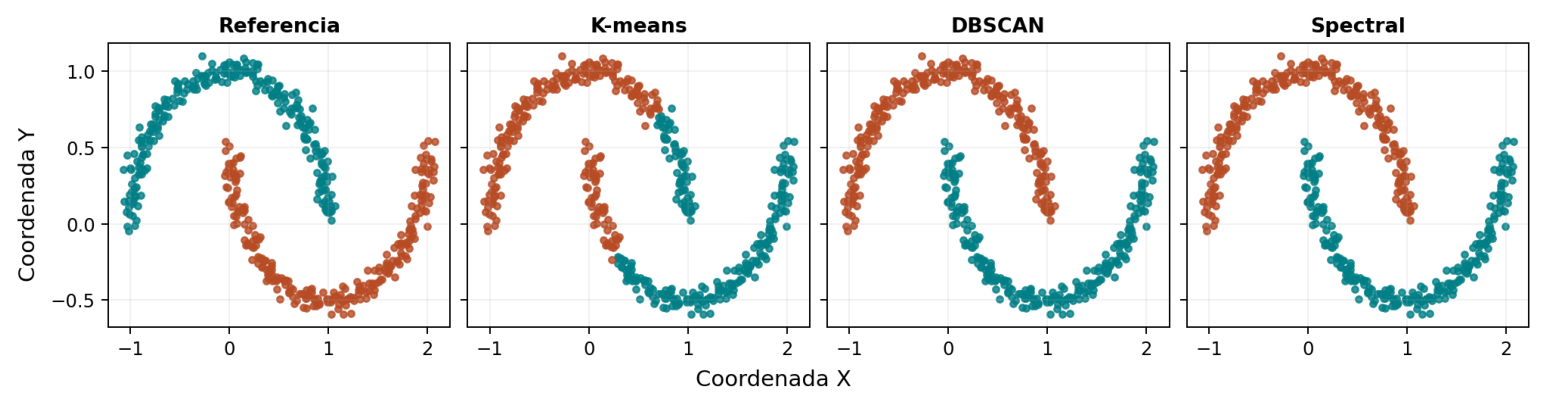

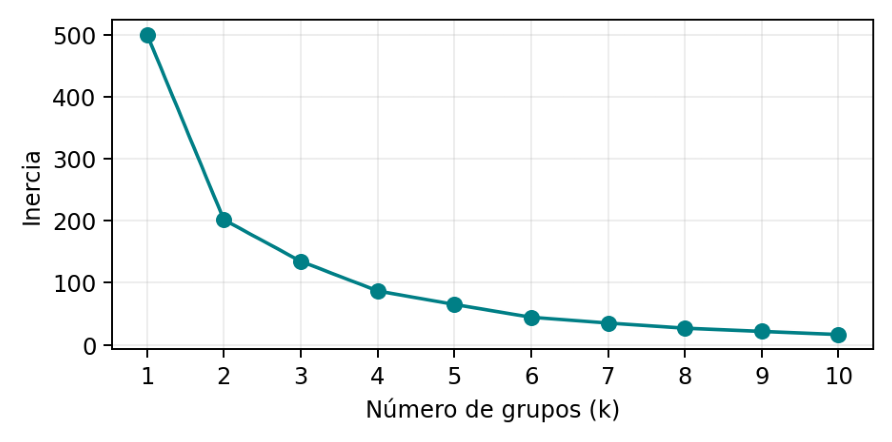

dataset   modelo  grupos  ruido  cobertura    ARI  V-measure  Silhouette  Davies-Bouldin
  Moons  K-means       2      0        1.0 0.2525      0.192      0.4893          0.7820
  Moons   DBSCAN       2      0        1.0 1.0000      1.000      0.3345          1.1518
  Moons Spectral       2      0        1.0 1.0000      1.000      0.3345          1.1518


In [5]:
run_case(cases[1])

### Interpretación
K-means separa mediante una recta y corta ambas lunas. DBSCAN conecta puntos de cada arco mediante vecindades densas y Spectral recupera los arcos con el grafo de vecinos.

DBSCAN y Spectral alcanzan ARI y V-measure de 1,000 con cobertura completa. K-means obtiene ARI 0,253 y V-measure 0,192, aunque su Silhouette es mayor (0,489 frente a 0,334) y su Davies-Bouldin es menor (0,782 frente a 1,152). Sus grupos son más compactos según distancias euclidianas.

La mayor caída de inercia aparece al pasar de k = 1 a k = 2 (501,10 a 201,93). Aun con dos grupos, la solución de K-means divide los arcos porque optimiza la proximidad a sus centroides.

## 7 Caso Circle
500 observaciones en dos anillos concéntricos. El radio interior es 0,45 veces el exterior y el ruido gaussiano tiene desviación estándar de 0,035. Se conservaron las coordenadas generadas.

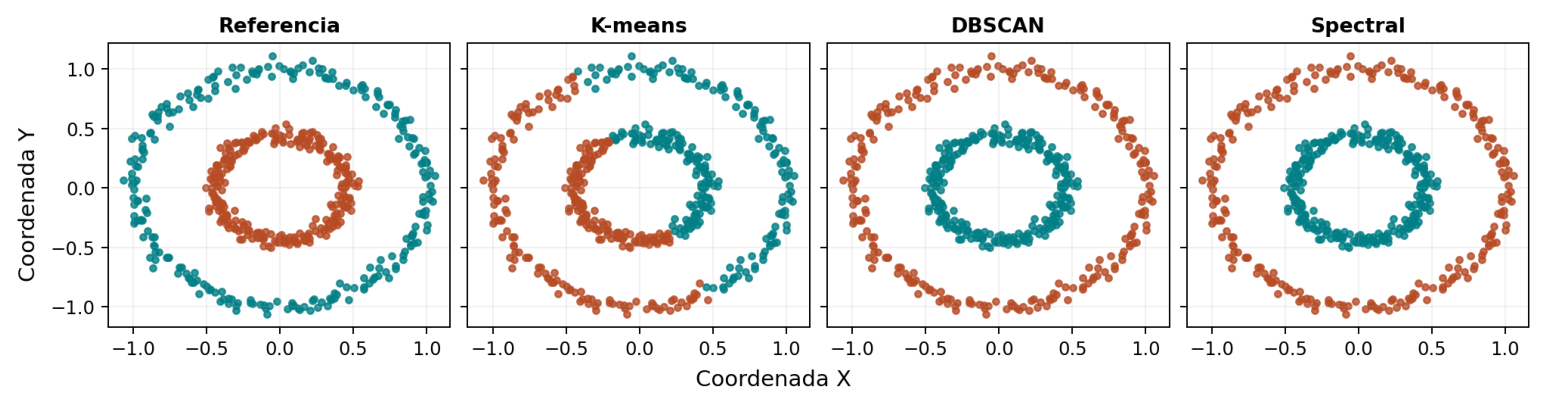

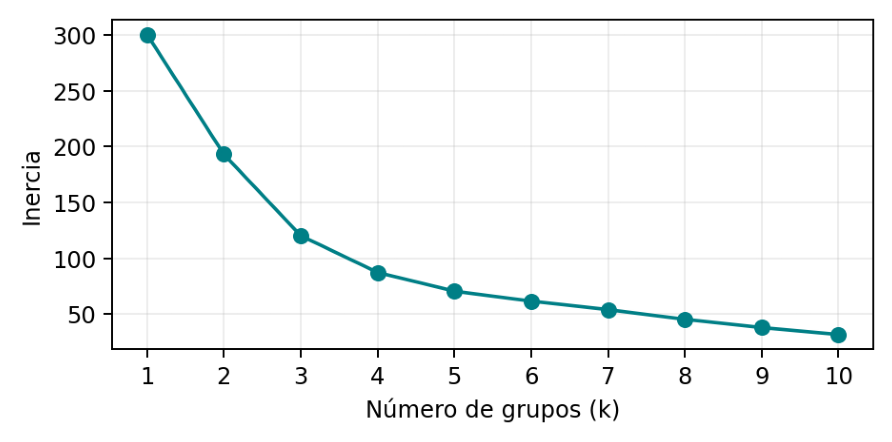

dataset   modelo  grupos  ruido  cobertura    ARI  V-measure  Silhouette  Davies-Bouldin
 Circle  K-means       2      0        1.0 -0.002        0.0      0.3433          1.1947
 Circle   DBSCAN       2      0        1.0  1.000        1.0      0.1361        304.3395
 Circle Spectral       2      0        1.0  1.000        1.0      0.1361        304.3395


In [6]:
run_case(cases[2])

### Interpretación
K-means corta los dos anillos en sectores. DBSCAN sigue la continuidad de cada anillo y Spectral separa los anillos a partir de las conexiones locales entre vecinos.

DBSCAN y Spectral alcanzan ARI y V-measure de 1,000. K-means tiene ARI ligeramente negativo (-0,002) y V-measure cercana a cero. Su Silhouette de 0,343 supera a 0,136 de los otros dos. En los anillos, los centroides casi coinciden y esa distancia pequeña eleva Davies-Bouldin a 304,339.

La inercia desciende de 300,45 a 193,09 y a 120,23 para k = 1, 2 y 3. La curva sigue bajando al subdividir los anillos en sectores compactos y el codo resulta menos claro.

## 8 Sensibilidad y distancias de vecinos
Variamos eps y n_neighbors para comprobar cómo cambian los grupos. Esto amplía el proyecto sin modificar los resultados base. Los valores son ilustrativos; no se elige el mejor modelo automáticamente por ARI.

El quinto vecino incluye el propio punto, igual que el conteo de min_samples. Las curvas orientan radios candidatos; no garantizan un óptimo.

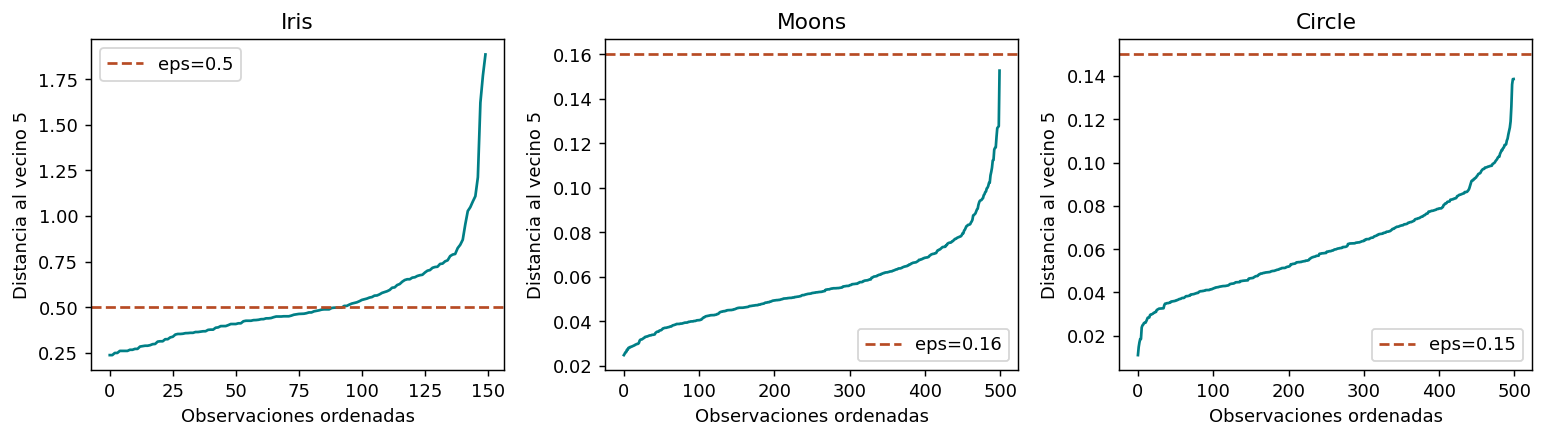

     parametro dataset   modelo  grupos  ruido  cobertura     ARI  V-measure  Silhouette  Davies-Bouldin
       eps=0.3    Iris   DBSCAN       3    120     0.2000  0.0876     0.2783      0.6302          0.4594
       eps=0.5    Iris   DBSCAN       2     34     0.7733  0.4421     0.5114      0.6559          0.4942
       eps=1.2    Iris   DBSCAN       2      1     0.9933  0.5584     0.7201      0.5868          0.5800
 n_neighbors=3    Iris Spectral       3      0     1.0000  0.1931     0.2628      0.0543          1.8212
n_neighbors=12    Iris Spectral       3      0     1.0000  0.5801     0.6166      0.4602          0.8322
n_neighbors=40    Iris Spectral       3      0     1.0000  0.6410     0.6728      0.4573          0.8343
      eps=0.06   Moons   DBSCAN      18     55     0.8900  0.1203     0.3586      0.4112          0.5536
      eps=0.16   Moons   DBSCAN       2      0     1.0000  1.0000     1.0000      0.3345          1.1518
       eps=0.6   Moons   DBSCAN       1      0     1.00

In [7]:
# Análisis adicional: no sustituye las nueve configuraciones base.
from sklearn.neighbors import NearestNeighbors
sensitivity=[]
for name,x,truth,k,eps,min_samples,neighbors in cases:
    for radius in {'Iris':[.3,.5,1.2],'Moons':[.06,.16,.6],'Circle':[.06,.15,.6]}[name]:
        labels=DBSCAN(eps=radius,min_samples=5).fit_predict(x)
        sensitivity.append({'parametro':f'eps={radius}',**evaluate(name,'DBSCAN',x,truth,labels)})
    for n in [3,12,40]:
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always')
            labels=SpectralClustering(n_clusters=k,affinity='nearest_neighbors',n_neighbors=n,
                     assign_labels='kmeans',n_init=20,random_state=SEED).fit_predict(x)
        notices.extend({'dataset':name,'modelo':f'Spectral vecinos={n}','aviso':str(w.message)} for w in caught)
        sensitivity.append({'parametro':f'n_neighbors={n}',**evaluate(name,'Spectral',x,truth,labels)})
pd.DataFrame(sensitivity).to_csv(OUTPUT/'sensibilidad.csv',index=False)
print(pd.DataFrame(sensitivity).round(4).to_string(index=False))
fig,axes=plt.subplots(1,3,figsize=(12,3.5))
for ax,(name,x,truth,k,eps,min_samples,neighbors) in zip(axes,cases):
    distances,_=NearestNeighbors(n_neighbors=5).fit(x).kneighbors(x)
    ax.plot(np.sort(distances[:,-1]),color='#007F86')
    ax.axhline(eps,ls='--',color='#B74B24',label=f'eps={eps}')
    ax.set_title(name);ax.set_xlabel('Observaciones ordenadas');ax.set_ylabel('Distancia al vecino 5');ax.legend()
fig.tight_layout();fig.savefig(OUTPUT/'distancias_vecinos.png',dpi=160);plt.show();plt.close(fig)


## 9 Exportar y verificar
Se conservan datos originales, métricas, contingencias, versiones y avisos. Un grafo desconectado puede corresponder a grupos reales separados o a fragmentación; se debe revisar.

In [8]:
import json,platform,sklearn,scipy,matplotlib
DATA=Path('datos');DATA.mkdir(exist_ok=True)
for name,raw,truth in [('Iris',iris,iris_labels),('Moons',moons,moons_labels),('Circle',circles,circle_labels)]:
    frame=pd.DataFrame(raw,columns=load_iris().feature_names if name=='Iris' else ['x1','x2'])
    frame['clase_real']=truth;frame.to_csv(DATA/f'{name}.csv',index=False)
write_csv('metricas.csv',metrics);write_csv('codo.csv',elbows)
pd.DataFrame(graph_info).to_csv(OUTPUT/'grafos.csv',index=False)
(OUTPUT/'advertencias.json').write_text(json.dumps(notices,indent=2,ensure_ascii=False),encoding='utf-8')
versions={'python':platform.python_version(),'scikit-learn':sklearn.__version__,'numpy':np.__version__,
          'pandas':pd.__version__,'scipy':scipy.__version__,'matplotlib':matplotlib.__version__}
(OUTPUT/'versiones.json').write_text(json.dumps(versions,indent=2),encoding='utf-8')
assert len(metrics)==9
assert all(0 <= row['cobertura'] <= 1 for row in metrics)
assert evaluate('test','test',moons,moons_labels,np.full(500,-1))['Silhouette'] is None
assert evaluate('test','test',moons,moons_labels,np.zeros(500,dtype=int))['Davies-Bouldin'] is None
print('Verificación correcta: nueve casos y manejo de todo ruido o un único grupo.')
print('Componentes del grafo:',graph_info)
print('Versiones:',versions)


Verificación correcta: nueve casos y manejo de todo ruido o un único grupo.
Componentes del grafo: [{'dataset': 'Iris', 'componentes': 1}, {'dataset': 'Moons', 'componentes': 2}, {'dataset': 'Circle', 'componentes': 2}]
Versiones: {'python': '3.12.14', 'scikit-learn': '1.8.0', 'numpy': '2.3.5', 'pandas': '2.2.3', 'scipy': '1.17.0', 'matplotlib': '3.10.8'}


## 10 Naturaleza de los modelos y conclusiones
| Modelo | Naturaleza | Hiperparámetros críticos |
|---|---|---|
| K-means | Frontera lineal entre cada par de centroides | n_clusters, init, n_init; escala, max_iter y tol |
| DBSCAN | No lineal por densidad | eps, min_samples, distancia y escala |
| Spectral | No lineal en el espacio original | n_clusters, affinity, n_neighbors; gamma si se usa RBF |

K-means no es una regresión lineal: se lo considera lineal aquí por sus fronteras entre centroides. En Spectral con nearest_neighbors, gamma no controla el grafo usado.

**Iris:** K-means obtiene la mayor coincidencia externa en la configuración recibida. DBSCAN agrupa 116 de 150 flores; su mejor Silhouette no significa mejor recuperación de tres especies.

**Moons y Circle:** DBSCAN y Spectral recuperan perfectamente las clases de referencia. K-means obtiene mejores métricas internas porque crea regiones compactas. En anillos, Davies-Bouldin es muy alto porque los centroides casi coinciden.

**Limitaciones:** una semilla, niveles de ruido fijos, k conocido y evaluación sobre los mismos datos agrupados. No se ha demostrado generalización a datos nuevos. Si cambias los parámetros, revisa las conclusiones redactadas y las cifras del Word.

**Referencias oficiales:**
- https://scikit-learn.org/stable/modules/clustering.html
- https://scikit-learn.org/stable/modules/generated/sklearn.metrics.adjusted_rand_score.html
- https://scikit-learn.org/stable/modules/generated/sklearn.metrics.v_measure_score.html
- https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html
- https://scikit-learn.org/stable/modules/generated/sklearn.metrics.davies_bouldin_score.html


## 11 Descargar los resultados
La última celda crea un ZIP. En Colab puedes descargarlo desde el panel Archivos.

In [9]:
import zipfile
with zipfile.ZipFile('Resultados_Clustering_Nuevo.zip','w',zipfile.ZIP_DEFLATED) as z:
    for folder in [DATA,OUTPUT]:
        for file in sorted(folder.glob('*')):
            if file.is_file():z.write(file,str(file))
print('Creado Resultados_Clustering_Nuevo.zip')

Creado Resultados_Clustering_Nuevo.zip
